# Aula 1 — Prática: seu primeiro ambiente computacional em bioinformática

**Disciplina:** Introdução à Bioinformática — PPGED / IME

Este caderno acompanha o Material de Apoio da Aula 1. Nele você refaz, **em código Python comentado**, o que vimos na teoria: mexer com pastas e arquivos, tratar sequências biológicas, ler arquivos FASTA e buscar dados em bancos públicos **por código** (APIs do NCBI e do PubChem).

| Parte | O que você vai fazer | Conceito da teoria |
|---|---|---|
| **0** | Instalar as bibliotecas e conferir seu ambiente | Python, bibliotecas, ambiente |
| **A** | Navegar por pastas e arquivos usando Python | Terminal: `pwd`, `ls`, `mkdir` |
| **B** | Tratar uma sequência de DNA como texto: contar bases, %GC, complemento reverso, transcrever e traduzir | DNA → RNA → proteína; Biopython |
| **C** | Escrever e ler um arquivo FASTA e organizar os dados numa tabela | Formato FASTA; Pandas |
| **D** | Baixar uma sequência real do NCBI por código | API, Entrez, *accession number* |
| **E** | Buscar um composto químico no PubChem por código | API, PUG-REST, CID |
| **F** | Registrar seus resultados em um arquivo | Reprodutibilidade e *pipeline* |

> **Tempo estimado:** Partes 0–C (sem internet) ≈ 30 min · Partes D–F (precisam de internet) ≈ 30 a 40 min.

---

### Primeira vez com um caderno (*notebook*)? Leia isto (2 minutos)

- Um **caderno** mistura **texto** (como este) e **células de código** (caixas com código).
- Para **executar** uma célula de código: clique nela e pressione **Shift + Enter** (ou clique no ▶ ao lado da célula).
- Execute as células **em ordem, de cima para baixo**. Cada uma usa o que as anteriores prepararam.
- Linhas que começam com `#` são **comentários**: explicações para humanos, que o computador ignora. **Leia os comentários** — eles são o material didático.
- Se algo travar ou ficar confuso, **reinicie o kernel** (botão *Restart* na barra do caderno) e execute tudo de novo, de cima para baixo.
- Você **não precisa** entender cada linha. Foque no **que** cada bloco faz e no **resultado** que ele mostra.
- Errar faz parte. No fim do caderno há uma seção de **problemas comuns**.

Este caderno funciona no **VS Code**, no **Jupyter** e no **Google Colab**.

---
# PARTE 0 — Preparação do ambiente

Python sozinho sabe fazer contas e manipular texto. Para tarefas especializadas usamos **bibliotecas**: pacotes de código prontos, escritos por outras pessoas. Hoje usaremos:

| Biblioteca | Para que serve aqui |
|---|---|
| **Biopython** | Ler, escrever e manipular sequências biológicas; acessar o NCBI (`Bio.Entrez`) |
| **requests** | Fazer pedidos a sites e APIs pela internet (vamos usar no PubChem) |
| **pandas** | Tabelas (como uma planilha do Excel dentro do Python) |
| **numpy** | Contas numéricas rápidas |

### Por que `%pip` e não `pip`?

A célula abaixo usa `%pip install`. O `%` é um comando especial do caderno que instala o pacote **exatamente no Python que está rodando este caderno**. É isso que evita o erro clássico `ModuleNotFoundError` (instalar num Python e rodar em outro). Se as bibliotecas já estiverem instaladas, nada acontece de errado: ele só confirma.

In [28]:
# Instala (ou confirma) as bibliotecas. O "-q" deixa a saída silenciosa.
# Pode levar de 10 a 60 segundos na primeira vez.
%pip install -q biopython requests pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [29]:
# ------------------------------------------------------------------
# Importa (carrega) as bibliotecas que vamos usar.
# "import X as Y" significa: carregue X e me deixe chamá-lo de Y (apelido curto).
# ------------------------------------------------------------------
import sys, platform, time               # utilitários do próprio Python (sistema, tempo)
from pathlib import Path                 # trabalhar com pastas e arquivos de forma simples
from io import StringIO                  # tratar um texto como se fosse um arquivo

import numpy as np                       # contas numéricas
import pandas as pd                      # tabelas
import requests                          # pedidos a APIs pela internet

import Bio                               # Biopython (a biblioteca inteira)
from Bio import Entrez, SeqIO            # Entrez = acesso ao NCBI; SeqIO = leitura/escrita de sequências
from Bio.Seq import Seq                  # objeto "sequência" com métodos prontos (complemento, tradução...)
from IPython.display import display, Image   # mostrar tabelas e imagens no caderno

# Mostra mais colunas ao imprimir tabelas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# ------------------------------------------------------------------
# >>> EDITE AQUI <<<  O NCBI exige que você se identifique com um e-mail.
# Pode ser o institucional (IME) ou o pessoal. Serve apenas para o NCBI
# contatar você caso o uso seja abusivo.
# ------------------------------------------------------------------
SEU_EMAIL = "alexmdbarros@gmail.com"
Entrez.email = SEU_EMAIL
if "exemplo.com" in SEU_EMAIL:
    print("⚠ Troque SEU_EMAIL pelo seu e-mail real antes de seguir para a Parte D.\n")

# Relatório do ambiente: útil para você e para o professor se algo der errado
print("Python    :", sys.version.split()[0], f"({platform.system()})")
print("Biopython :", Bio.__version__)
print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("requests  :", requests.__version__)
print("\nTudo pronto! Pode seguir para a Parte A.")

Python    : 3.14.6 (Windows)
Biopython : 1.88
pandas    : 3.0.3
numpy     : 2.4.6
requests  : 2.34.2

Tudo pronto! Pode seguir para a Parte A.


---
# PARTE A — O "terminal" dentro do Python: pastas e arquivos

Na aula vimos os comandos básicos do terminal. O Python consegue fazer **as mesmas coisas** com código — e funciona igual em Windows, macOS e Linux (no terminal, `ls` não existe no Windows comum, mas o código abaixo funciona em qualquer sistema).

| No terminal | O que faz | No Python (neste caderno) |
|---|---|---|
| `pwd` | Mostra em qual pasta você está | `Path.cwd()` |
| `ls` | Lista os arquivos da pasta | `pasta.iterdir()` |
| `mkdir` | Cria uma pasta | `pasta.mkdir(exist_ok=True)` |
| `cd` | Entra em uma pasta | usar o caminho: `pasta / "arquivo.txt"` |
| `cp` / `mv` | Copia / move arquivos | `shutil.copy` / `shutil.move` |

> O **diretório de trabalho** é a pasta onde o caderno está rodando. Tudo o que o código salvar vai para lá (ou para dentro de uma subpasta que vamos criar).

In [30]:
# "pwd": em qual pasta este caderno está rodando?
print("Pasta atual:", Path.cwd())

# "mkdir": cria uma subpasta para guardar os arquivos da aula.
# exist_ok=True significa: se a pasta já existir, tudo bem, não dê erro.
PASTA = Path("bioinfo_aula1")
PASTA.mkdir(exist_ok=True)
print("Pasta de trabalho da aula:", PASTA.resolve())

# "ls": lista o que existe na pasta atual (arquivos e pastas), em ordem alfabética
print("\nConteúdo da pasta atual:")
for item in sorted(Path.cwd().iterdir()):
    tipo = "[pasta]  " if item.is_dir() else "[arquivo]"
    print(f"  {tipo} {item.name}")

Pasta atual: c:\Users\Legion\Bioinfo\Práticas
Pasta de trabalho da aula: C:\Users\Legion\Bioinfo\Práticas\bioinfo_aula1

Conteúdo da pasta atual:
  [arquivo] Aula 01 - Intro.ipynb
  [arquivo] Aula 02 - Alinhamento.ipynb
  [arquivo] Aula 03 - Genoma.ipynb
  [arquivo] Aula 04 - Transcriptoma.ipynb
  [arquivo] Aula 05 - Proteoma.ipynb
  [arquivo] Aula 06 - Epigenoma.ipynb
  [arquivo] Aula 07 - Estrutural.ipynb
  [arquivo] Aula 08 - Filogenia.ipynb
  [arquivo] Aula 09 - Metaboloma.ipynb
  [pasta]   bioinfo_aula1
  [arquivo] pipeline_alinhamento_blast.py
  [arquivo] Pratica1_AlMdBar.ipynb
  [arquivo] Pratica2_AlMdBar.ipynb
  [arquivo] Pratica3_AlMdBar.ipynb
  [arquivo] Pratica4_AlMdBar.ipynb
  [arquivo] Pratica5_AlMdBar.ipynb


**Pergunta A.1** — A pasta atual é a mesma onde você abriu o terminal no Passo 5 do roteiro? Se não for, tudo bem: o importante é saber **onde** seus arquivos estão sendo salvos. Anote o caminho impresso acima.

> **Resposta.** A pasta de trabalho foi `c:\Users\Legion\Bioinfo\Práticas`, e a subpasta da aula ficou em
> `...\Práticas\bioinfo_aula1`.

---
# PARTE B — Sequências biológicas como texto

Uma sequência de DNA é, para o computador, **um texto** formado por quatro letras: **A, T, C, G**. Isso é ótimo: tudo o que o Python sabe fazer com texto (contar, fatiar, comparar) já funciona com sequências.

Vamos usar uma sequência curta e didática (de exemplo, usada nos tutoriais do Biopython). Ela contém um pequeno gene, que começa com `ATG` (códon de início) e termina em um códon de parada.

In [31]:
# A sequência é uma variável do tipo texto (string), entre aspas.
dna = "ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG"

# len() conta quantos caracteres (bases) o texto tem
print("Tamanho da sequência:", len(dna), "bases")

# Fatiamento: dna[a:b] pega do caractere a até o b-1. A contagem começa em ZERO.
print("Primeiras 9 bases   :", dna[:9])
print("Últimas 9 bases     :", dna[-9:])

# Contagem de cada base com um laço (for): repete o bloco para cada letra de "ATCG"
contagem = {}                       # dicionário: guarda pares "letra -> quantidade"
for base in "ATCG":
    contagem[base] = dna.count(base)
print("Contagem de bases   :", contagem)

# Conferência: a soma das contagens deve ser igual ao tamanho (senão há letras estranhas)
print("Soma das contagens  :", sum(contagem.values()), "(deve ser igual ao tamanho)")

Tamanho da sequência: 39 bases
Primeiras 9 bases   : ATGGCCATT
Últimas 9 bases     : GCCCGATAG
Contagem de bases   : {'A': 9, 'T': 8, 'C': 8, 'G': 14}
Soma das contagens  : 39 (deve ser igual ao tamanho)


### Conteúdo GC

O **conteúdo GC** é a porcentagem de bases que são **G** ou **C**. Ele importa porque pares G–C têm três ligações de hidrogênio e A–T apenas duas: regiões ricas em GC são mais estáveis. O %GC também varia entre espécies, e por isso é usado para caracterizar genomas (e até para identificar a origem de uma sequência).

$$ \%GC = \frac{G + C}{\text{tamanho total}} \times 100 $$

Vamos escrever uma **função**: um bloco de código reutilizável, com nome. Assim podemos calcular o %GC de qualquer sequência sem copiar e colar o código.

In [32]:
def gc_percentual(sequencia):
    """Devolve o conteúdo GC (em %) de uma sequência (texto ou objeto Seq)."""
    texto = str(sequencia).upper()                 # garante letras maiúsculas e vira texto
    if len(texto) == 0:
        return 0.0                                 # evita divisão por zero
    return (texto.count("G") + texto.count("C")) / len(texto) * 100

print(f"%GC da sequência de exemplo: {gc_percentual(dna):.1f}%")

# Conferência com a função pronta do Biopython (existe em versões recentes)
try:
    from Bio.SeqUtils import gc_fraction
    print(f"Conferência (Biopython)    : {gc_fraction(dna) * 100:.1f}%")
except ImportError:
    print("(Sua versão do Biopython não tem gc_fraction; sem problema, nossa função já resolve.)")

%GC da sequência de exemplo: 56.4%
Conferência (Biopython)    : 56.4%


### O objeto `Seq` do Biopython e o dogma central

O Biopython tem um objeto `Seq` que é "um texto que entende de biologia". Com ele fazemos, em uma linha, o que a célula faz:

| Operação | Método | O que acontece na biologia |
|---|---|---|
| Complemento | `.complement()` | Cada base troca de par: A↔T, C↔G |
| Complemento reverso | `.reverse_complement()` | A **outra fita** do DNA, lida na direção correta (5' → 3') |
| Transcrição | `.transcribe()` | DNA → **RNA**: troca T por U |
| Tradução | `.translate()` | RNA/DNA → **proteína**: lê de 3 em 3 bases (códons), cada trinca = 1 aminoácido |

O **asterisco `*`** na proteína representa um **códon de parada** (a tradução termina ali).

In [33]:
seq = Seq(dna)        # transforma o texto em objeto Seq

print("DNA original       :", seq)
print("Complemento        :", seq.complement())
print("Complemento reverso:", seq.reverse_complement())
print()

rna = seq.transcribe()                 # T vira U
print("RNA (transcrição)  :", rna)

proteina = seq.translate()             # lê códon a códon
print("Proteína (tradução):", proteina)

# to_stop=True interrompe no primeiro códon de parada: dá a proteína "de verdade"
proteina_real = seq.translate(to_stop=True)
print("Até o 1º códon de parada:", proteina_real, f"({len(proteina_real)} aminoácidos) Tamanho do DNA: {len(seq)}")
print(f"Complemento: {seq.complement()} Complement reverso com sua string revertida: {seq.reverse_complement()[::-1]}. São iguais? { "Sim " if seq.complement() == seq.reverse_complement()[::-1] else "Não"}")

DNA original       : ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG
Complemento        : TACCGGTAACATTACCCGGCGACTTTCCCACGGGCTATC
Complemento reverso: CTATCGGGCACCCTTTCAGCGGCCCATTACAATGGCCAT

RNA (transcrição)  : AUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG
Proteína (tradução): MAIVMGR*KGAR*
Até o 1º códon de parada: MAIVMGR (7 aminoácidos) Tamanho do DNA: 39
Complemento: TACCGGTAACATTACCCGGCGACTTTCCCACGGGCTATC Complement reverso com sua string revertida: TACCGGTAACATTACCCGGCGACTTTCCCACGGGCTATC. São iguais? Sim 


**Pergunta B.1** — Quantos aminoácidos tem a proteína "de verdade" (até o primeiro `*`)? Cada aminoácido corresponde a quantas bases? Confira com o tamanho do DNA.
    
    7 aminoácidos. Cada aminoácido corresponde a 3 bases. 7*3 = 21 bases






**Pergunta B.2** — Qual a diferença entre o **complemento** e o **complemento reverso**? Dica: as duas fitas do DNA são **antiparalelas**; para ler a outra fita na direção certa, é preciso inverter a ordem.

    Somente a ordem, um deles está invertido.


---
# PARTE C — Formato FASTA: escrever, ler e organizar

Um arquivo **FASTA** tem, para cada sequência: uma linha de cabeçalho começando com `>` e, em seguida, a sequência. Vamos **criar** um arquivo com duas sequências didáticas, **lê-lo** com o Biopython e organizar as informações em uma **tabela do Pandas**.

In [34]:
# Texto de um FASTA com duas sequências (inventadas, só para treinar).
# Repare: cada registro tem UMA linha de cabeçalho (>) e depois a sequência.
fasta_exemplo = """>gene_exemplo_1 Sequência didática 1
ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG
>gene_exemplo_2 Sequência didática 2
ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCACAGGTAACGGTGCGGGCTGA
"""

# Escreve o texto num arquivo dentro da pasta da aula.
# "with open(...)" abre o arquivo e o fecha sozinho ao terminar.
caminho_fasta = PASTA / "exemplo.fasta"
with open(caminho_fasta, "w") as arquivo:
    arquivo.write(fasta_exemplo)
print("Arquivo criado:", caminho_fasta)

# "Olhar" o arquivo, como faria o comando "head" no terminal: mostra as primeiras linhas
print("\nConteúdo do arquivo:")
with open(caminho_fasta) as arquivo:
    for numero, linha in enumerate(arquivo, start=1):
        print(f"{numero:>2} | {linha.rstrip()}")

Arquivo criado: bioinfo_aula1\exemplo.fasta

Conteúdo do arquivo:
 1 | >gene_exemplo_1 Sequência didática 1
 2 | ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG
 3 | >gene_exemplo_2 Sequência didática 2
 4 | ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCACAGGTAACGGTGCGGGCTGA


In [35]:
# Lê o FASTA com o Biopython. SeqIO.parse devolve um registro por sequência.
registros = list(SeqIO.parse(caminho_fasta, "fasta"))
print(f"{len(registros)} sequências lidas\n")

# Monta uma tabela (DataFrame) com uma linha por sequência
linhas = []
for registro in registros:
    linhas.append({
        "id": registro.id,                              # 1ª palavra do cabeçalho
        "descrição": registro.description,              # cabeçalho completo
        "tamanho (bases)": len(registro.seq),
        "%GC": round(gc_percentual(registro.seq), 1),
        "proteína": str(registro.seq.translate(to_stop=True)),
    })
tabela = pd.DataFrame(linhas)
display(tabela)

# NumPy e Pandas calculam estatísticas em uma linha
print(f"\n%GC médio das sequências: {tabela['%GC'].mean():.1f}%")
print(f"Maior sequência          : {tabela.loc[tabela['tamanho (bases)'].idxmax(), 'id']}")

2 sequências lidas



,id,descrição,tamanho (bases),%GC,proteína
0,gene_exemplo_1,gene_exemplo_1 Sequência didática 1,39,56.4,MAIVMGR
1,gene_exemplo_2,gene_exemplo_2 Sequência didática 2,66,51.5,MKRISTTITTTITITTGNGAG



%GC médio das sequências: 54.0%
Maior sequência          : gene_exemplo_2


**Pergunta C.1** — Qual das duas sequências tem maior conteúdo GC? E qual codifica a proteína mais longa?

        gene_exemplo_1 possui o GC maior. Contudo, o que codifica a proteína mais longa é o gene_exemplo_2.


---
# PARTE D — Baixando uma sequência real do NCBI por código

> **A partir daqui você precisa de internet.** As células já trazem tratamento de erro: se o servidor falhar, elas avisam em vez de travar o caderno.

### Lembrando: o que é uma API?

Pense na API como um **garçom**: você faz um pedido por um "cardápio" padronizado e ele traz exatamente o que você pediu da "cozinha" (o banco de dados), sem você precisar entrar nela. No NCBI, esse cardápio se chama **Entrez**, e o Biopython o acessa pelo módulo `Bio.Entrez`.

| Função do Entrez | O que pede ao NCBI |
|---|---|
| `Entrez.efetch(...)` | **Buscar** (baixar) o registro cujo identificador você já conhece |
| `Entrez.esearch(...)` | **Pesquisar** por um termo e receber a lista de identificadores encontrados |
| `Entrez.esummary(...)` | Receber um **resumo** (título, tamanho...) de uma lista de identificadores |

**Boas práticas com servidores públicos:**
- Identifique-se com um e-mail (`Entrez.email`, já configurado na Parte 0).
- Sem **API key**, o limite é de **3 pedidos por segundo**. Por isso fazemos pequenas pausas (`time.sleep`) entre pedidos.
- (Opcional) Uma API key gratuita sobe o limite para 10/s: crie em <https://www.ncbi.nlm.nih.gov/account/> e adicione `Entrez.api_key = "sua_chave"`.

In [36]:
def baixar_sequencia_ncbi(accession, db="nucleotide", tentativas=3):
    """Baixa UM registro do NCBI em formato FASTA e devolve um objeto de sequência.

    accession : o número de acesso (ex.: "NC_045512.2")
    db        : "nucleotide" para DNA/RNA; "protein" para proteínas
    tentativas: quantas vezes tentar de novo se o servidor falhar por instantes

    Devolve None se não conseguir (o caderno não trava).
    """
    Entrez.api_key = "b469956248b68f1d8442448a04626ae43607"
    for tentativa in range(1, tentativas + 1):
        try:
            # O "pedido ao garçom": id = o que queremos; rettype = em que formato
            handle = Entrez.efetch(db=db, id=accession, rettype="fasta", retmode="text")
            try:
                return SeqIO.read(handle, "fasta")     # lê a resposta como FASTA
            finally:
                handle.close()                         # fecha a conexão, aconteça o que acontecer
        except Exception as erro:
            print(f"  tentativa {tentativa} de {tentativas} falhou: {str(erro)[:150]}")
            if tentativa < tentativas:
                time.sleep(2 * tentativa)              # espera 2s, depois 4s...
    return None

print("Função baixar_sequencia_ncbi definida.")

Função baixar_sequencia_ncbi definida.


In [37]:
# ------------------------------------------------------------------
# >>> EDITE AQUI <<<
# Use o número de acesso (accession) que você anotou no Passo 7 do roteiro
# (busca manual no site do NCBI). Se não anotou, mantenha este: é o genoma de
# referência do SARS-CoV-2 (cerca de 29,9 mil bases), uma sequência pequena e bem conhecida.
# ------------------------------------------------------------------
ACCESSION = "NC_045512.2"

registro = baixar_sequencia_ncbi(ACCESSION)

if registro is None:
    print("\n✘ Não consegui baixar agora. Confira: (1) a internet, (2) se o accession está certo,")
    print("  (3) se você trocou SEU_EMAIL na Parte 0. Depois rode esta célula de novo.")
else:
    print(f"\n✔ Baixado: {registro.id}")
    print("Descrição :", registro.description)
    print("Tamanho   :", f"{len(registro.seq):,}", "bases")
    print(f"%GC       : {gc_percentual(registro.seq):.1f}%")
    print(f"Primeiras 100 bases: {registro.seq[:100]} com o total sendo: {len(registro.seq)}")

    # Salva em FASTA na pasta da aula (o mesmo que "Send to → File → FASTA" no site)
    caminho_ncbi = PASTA / f"{ACCESSION}.fasta"
    SeqIO.write(registro, caminho_ncbi, "fasta")
    print("\nArquivo salvo em:", caminho_ncbi)


✔ Baixado: NC_045512.2
Descrição : NC_045512.2 Severe acute respiratory syndrome coronavirus 2 isolate Wuhan-Hu-1, complete genome
Tamanho   : 29,903 bases
%GC       : 38.0%
Primeiras 100 bases: ATTAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGCTGTCACTC com o total sendo: 29903

Arquivo salvo em: bioinfo_aula1\NC_045512.2.fasta


**Pergunta D.1** — O tamanho e a descrição batem com o que você viu no site do NCBI no Passo 7? Quanto tempo você levou para obter a sequência manualmente, e quanto levou por código? Imagine repetir isso para 500 sequências.

        Cerca de 2 minutos manualmente. Em Código foi instantâneo.


### Pesquisando por termo (em vez de já saber o accession)

Na prática, muitas vezes **não sabemos o accession**: sabemos o assunto. O `esearch` faz a pesquisa e devolve os identificadores; o `esummary` traz um resumo de cada um. Vamos buscar **proteínas do *Bacillus anthracis* (agente do antraz) com "protective antigen" no título** — o antígeno protetor é um componente central da toxina do antraz e alvo de vacinas, um tema clássico de biodefesa.

A sintaxe da pesquisa é a mesma do site: `"termo"[Campo]` e operadores `AND`, `OR`, `NOT`.

In [38]:
# >>> EDITE AQUI <<< (tente outros termos depois!)
TERMO = '"Bacillus anthracis"[Organism] AND "protective antigen"[Title]'
BASE = "protein"          # "protein" para proteínas; "nucleotide" para DNA/RNA
MAXIMO = 5                # quantos resultados queremos ver

try:
    # 1) esearch: devolve QUANTOS registros existem e uma lista de identificadores (IDs)
    handle = Entrez.esearch(db=BASE, term=TERMO, retmax=MAXIMO)
    busca = Entrez.read(handle)      # Entrez.read converte a resposta (XML) em dicionário Python
    handle.close()
    print(f"Registros encontrados no NCBI: {busca['Count']} (mostrando até {MAXIMO})")

    ids = list(busca["IdList"])
    if not ids:
        print("Nenhum resultado. Tente simplificar o termo de busca.")
    else:
        time.sleep(0.4)              # pausa de cortesia (limite de 3 pedidos por segundo)

        # 2) esummary: título, tamanho e accession de cada ID
        handle = Entrez.esummary(db=BASE, id=",".join(ids))
        resumos = Entrez.read(handle)
        handle.close()

        resultados = pd.DataFrame([{
            "accession": str(r.get("AccessionVersion", r.get("Caption", ""))),
            "tamanho": int(r.get("Length", 0)),
            "título": str(r.get("Title", "")),
        } for r in resumos])
        display(resultados)
except Exception as erro:
    print("Não consegui pesquisar no NCBI agora:", erro)
    print("Tente de novo em instantes. Você pode seguir para a Parte E.")

Registros encontrados no NCBI: 365 (mostrando até 5)


,accession,tamanho,título
0,25PV_A,427,"Chain A, Protective antigen PA-63"
1,3TEZ_A,735,"Chain A, Protective antigen"
2,XLV53974.1,189,"toxin protective antigen, partial [Bacillus an..."
3,3TEY_A,715,"Chain A, Protective antigen"
4,XKO80166.1,764,anthrax toxin protective antigen (plasmid) [Ba...


**Pergunta D.2** — Escolha um accession da tabela e baixe-o com `baixar_sequencia_ncbi("<accession>", db="protein")`. Que tamanho tem a proteína (em aminoácidos)?

> **Resposta.** O próprio `esummary` da célula anterior já informa o tamanho: `3TEZ_A` tem **735 aminoácidos** e
> `XKO80166.1` tem **764**.

---
# PARTE E — Buscando um composto químico no PubChem por código

O **PubChem** é o banco público de **moléculas pequenas** (fármacos, ligantes, compostos). Cada composto tem um **CID** (*Compound ID*). Ele será útil no docking molecular, quando usarmos moléculas como ligantes.

### Como montar um pedido ao PubChem (PUG-REST)

O endereço do pedido tem três partes, separadas por `/`:

```
https://pubchem.ncbi.nlm.nih.gov/rest/pug / compound/name/ciprofloxacin / property/MolecularFormula,MolecularWeight / JSON
                                            └── ENTRADA ───────────────┘ └── OPERAÇÃO ────────────────────────────┘ └ SAÍDA ┘
```

- **Entrada:** o que você já sabe (aqui, o **nome** do composto, em inglês).
- **Operação:** o que você quer saber (fórmula, peso molecular, estrutura em SMILES...).
- **Saída:** o formato da resposta. **JSON** é um texto organizado em pares *chave: valor*, fácil de ler no Python.

### Códigos de status (a "resposta do garçom")

| Código | Significa | O que fazer |
|---|---|---|
| `200` | Deu certo | Use os dados |
| `404` | Composto não encontrado | Confira o nome (em inglês!) |
| `503` | Servidor ocupado | **Espere e tente de novo** (a função abaixo já faz isso) |

A função abaixo usa **tentativas com espera crescente** (5 s, 10 s, 20 s...): se o servidor estiver ocupado, esperamos mais a cada vez, em vez de insistir e piorar o congestionamento.

In [39]:
def buscar_composto(nome, tentativas=5, espera=5):
    """Busca um composto no PubChem pelo NOME (em inglês) e devolve um dicionário.

    Devolve None se não encontrar ou se o servidor continuar indisponível.
    """
    # requests.utils.quote protege caracteres especiais do nome (ex.: espaços)
    nome_url = requests.utils.quote(nome)
    url = ("https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/"
           f"{nome_url}/property/MolecularFormula,MolecularWeight,CanonicalSMILES/JSON")

    for tentativa in range(1, tentativas + 1):
        try:
            resposta = requests.get(url, timeout=30)
            try:
                dados = resposta.json()
            except ValueError:               # a resposta não era JSON (ex.: página de erro)
                dados = {}

            if resposta.status_code == 200 and "PropertyTable" in dados:
                p = dados["PropertyTable"]["Properties"][0]
                # O PubChem renomeou a propriedade do SMILES; aceitamos qualquer um dos nomes.
                smiles = next((p[k] for k in ("ConnectivitySMILES", "CanonicalSMILES", "SMILES")
                               if k in p), "não disponível")
                return {"composto": nome, "CID": p["CID"], "fórmula": p["MolecularFormula"],
                        "peso molecular": float(p["MolecularWeight"]), "SMILES": smiles}

            if resposta.status_code == 404:  # nome não existe: tentar de novo não adianta
                print(f"  '{nome}': composto não encontrado (confira o nome, em inglês).")
                return None

            motivo = dados.get("Fault", {}).get("Message", f"status {resposta.status_code}")
            print(f"  tentativa {tentativa} de {tentativas} falhou: {motivo}")
        except requests.RequestException as erro:     # sem internet, tempo esgotado etc.
            print(f"  tentativa {tentativa} de {tentativas} falhou: sem conexão com o PubChem ({type(erro).__name__})")

        if tentativa < tentativas:
            print(f"  aguardando {espera}s antes de tentar de novo...")
            time.sleep(espera)
            espera *= 2                                # dobra a espera a cada nova tentativa
    return None

print("Função buscar_composto definida.")

Função buscar_composto definida.



✔ ciprofloxacin
  CID            : 2764
  fórmula        : C17H18FN3O3
  peso molecular : 331.34
  SMILES         : C1CC1N2C=C(C(=O)C3=CC(=C(C=C32)N4CCNCC4)F)C(=O)O

Anote o CID: ele será reutilizado no docking molecular.


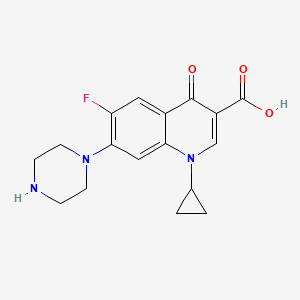

In [40]:
# >>> EDITE AQUI <<< (use o nome em inglês: "penicillin", "caffeine", "atropine"...)
NOME_COMPOSTO = "ciprofloxacin"

composto_info = buscar_composto(NOME_COMPOSTO)

if composto_info is None:
    print("\n✘ Não consegui obter o composto agora.")
    print("  Se o erro foi 503, é instabilidade do PubChem (comum com a turma toda consultando).")
    print("  Teste a URL no navegador; se o erro aparecer lá também, espere alguns minutos.")
else:
    print(f"\n✔ {composto_info['composto']}")
    for chave in ("CID", "fórmula", "peso molecular", "SMILES"):
        print(f"  {chave:<15}: {composto_info[chave]}")
    print("\nAnote o CID: ele será reutilizado no docking molecular.")

    # Bônus: o PubChem também entrega o DESENHO da molécula (imagem PNG)
    try:
        url_imagem = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{composto_info['CID']}/PNG"
        display(Image(data=requests.get(url_imagem, timeout=30).content))
    except Exception:
        print("(Não consegui carregar a imagem da molécula, mas os dados acima estão corretos.)")

**Pergunta E.1** — O que significa o texto do **SMILES**? Ele descreve a estrutura da molécula como uma linha de texto (átomos e ligações). Procure o composto no site do PubChem e compare a estrutura desenhada com essa linha.

> **Resposta.** O SMILES descreve o **grafo molecular** como uma linha de texto
> `C1CC1N2C=C(C(=O)C3=CC(=C(C=C32)N4CCNCC4)F)C(=O)O`

### Comparando vários compostos de uma vez

Aqui a automação mostra seu valor: o mesmo código, repetido para uma lista. Escolhemos dois antibióticos usados no tratamento do antraz (ciprofloxacina e doxiciclina) e a atropina (antídoto usado em intoxicações por agentes neurotóxicos). Fazemos uma **pausa de 1 segundo** entre os pedidos, por educação com o servidor.

In [41]:
# >>> EDITE AQUI <<< (troque ou acrescente nomes, em inglês)
LISTA_COMPOSTOS = ["ciprofloxacin", "doxycycline", "atropine"]

resultados_quimicos = []
for nome in LISTA_COMPOSTOS:
    informacao = buscar_composto(nome, tentativas=3, espera=3)   # menos tentativas: são vários pedidos
    if informacao is not None:
        resultados_quimicos.append(informacao)
    time.sleep(1)           # pausa de cortesia entre pedidos

if resultados_quimicos:
    tabela_quimica = pd.DataFrame(resultados_quimicos).sort_values("peso molecular")
    display(tabela_quimica[["composto", "CID", "fórmula", "peso molecular"]].reset_index(drop=True))
else:
    print("Nenhum composto obtido agora (veja as mensagens acima).")

,composto,CID,fórmula,peso molecular
0,atropine,174174,C17H23NO3,289.40
1,ciprofloxacin,2764,C17H18FN3O3,331.34
2,doxycycline,54671203,C22H24N2O8,444.40


**Pergunta E.2** — Qual composto é o mais pesado? Esse peso é a massa de **uma molécula** ou de **um mol**? (Dica: a unidade usual é g/mol, ou Dalton para uma molécula.)

> **Resposta.** O mais pesado é a **doxiciclina (444,40)**.

---
# PARTE F — Fechamento: registrando seus resultados

Um resultado que só existe na tela some quando você fecha o caderno. Vamos gravar o que obtivemos em um **arquivo CSV** (que o Excel abre). Esse é o seu primeiro **mini pipeline**: dados públicos → código → tabela salva. Qualquer pessoa que rodar o seu caderno obtém o mesmo arquivo: isso é **reprodutibilidade**.

In [42]:
# Se alguma busca de rede falhou, as variáveis abaixo não existem ou valem None;
# "globals().get" devolve None em vez de dar erro, e o caderno segue em frente.
registro_final  = globals().get("registro")
composto_final  = globals().get("composto_info")

resumo = {
    "accession": globals().get("ACCESSION"),
    "tamanho (bases)": len(registro_final.seq) if registro_final is not None else None,
    "%GC": round(gc_percentual(registro_final.seq), 1) if registro_final is not None else None,
    "composto": composto_final["composto"] if composto_final else None,
    "CID": composto_final["CID"] if composto_final else None,
}
tabela_resumo = pd.DataFrame([resumo])
display(tabela_resumo)

caminho_resumo = PASTA / "resumo_aula1.csv"
tabela_resumo.to_csv(caminho_resumo, index=False)
print("\nResumo salvo em:", caminho_resumo.resolve())

print("\nArquivos criados nesta aula:")
for arquivo in sorted(PASTA.iterdir()):
    print(f"  {arquivo.name}  ({arquivo.stat().st_size:,} bytes)")

print("\n➜ Traga o accession e o CID para a próxima aula: vamos retomá-los nas unidades seguintes.")

,accession,tamanho (bases),%GC,composto,CID
0,NC_045512.2,29903,38.0,ciprofloxacin,2764



Resumo salvo em: C:\Users\Legion\Bioinfo\Práticas\bioinfo_aula1\resumo_aula1.csv

Arquivos criados nesta aula:
  exemplo.fasta  (185 bytes)
  NC_045512.2.fasta  (30,999 bytes)
  resumo_aula1.csv  (87 bytes)

➜ Traga o accession e o CID para a próxima aula: vamos retomá-los nas unidades seguintes.


---
# Conexão com a teoria

| Célula deste caderno | Conceito da aula |
|---|---|
| `%pip install` e relatório de versões | Ambiente, bibliotecas, reprodutibilidade |
| `Path.cwd()`, `mkdir`, `iterdir()` | Terminal: `pwd`, `mkdir`, `ls` |
| `dna.count(...)`, `gc_percentual(...)` | Sequência como texto; conteúdo GC |
| `Seq.transcribe()` / `.translate()` | Dogma central: DNA → RNA → proteína |
| `SeqIO.parse(...)` e o arquivo `exemplo.fasta` | Formato FASTA; Biopython |
| `pd.DataFrame(...)` | Pandas: tabelas |
| `Entrez.efetch` / `esearch` / `esummary` | API do NCBI; *accession number* |
| `requests.get` + JSON + status `503` | API do PubChem (PUG-REST); CID |
| `time.sleep` e tentativas com espera | Boas práticas com servidores públicos |
| `resumo_aula1.csv` | Pipeline reprodutível |

# Exercícios

1. **Sua sequência.** Troque o valor de `dna` (Parte B) por uma sequência curta sua e calcule o %GC e a proteína. *(Cuidado: o tamanho deve ser múltiplo de 3 para traduzir sem aviso.)*
2. **Três quadros de leitura.** Uma sequência de DNA pode ser lida de 3 jeitos, começando na 1ª, 2ª ou 3ª base. Traduza `seq[0:]`, `seq[1:]` e `seq[2:]`. *Dica:* corte o final para o tamanho ser múltiplo de 3, por exemplo `seq[1:1 + 3 * ((len(seq) - 1) // 3)]`.
3. **Complemento reverso e GC.** O %GC muda ao se tomar o complemento reverso? Por quê?
4. **Seu accession.** Troque `ACCESSION` (Parte D) pelo que você encontrou no site do NCBI. Compare tamanho e %GC com os do SARS-CoV-2.
5. **Uma proteína.** Baixe uma proteína com `baixar_sequencia_ncbi("<accession de proteína>", db="protein")` e traduza o gene correspondente da Parte B para comparar os tamanhos.
6. **Outra pesquisa.** Mude `TERMO` (Parte D) para algo da sua pesquisa (organismo, gene, proteína) e leia os resultados.
7. **Seus compostos.** Troque a `LISTA_COMPOSTOS` (Parte E) por três compostos do seu interesse e compare os pesos moleculares.
8. **Desafio.** Escreva um laço `for` que baixe **três accessions** do NCBI (com `time.sleep(0.4)` entre eles) e monte uma tabela com tamanho e %GC de cada um.

# Problemas comuns

**`ModuleNotFoundError: No module named 'Bio'` (ou `requests`, `pandas`...).**
O caderno está rodando em um Python diferente daquele onde o pacote foi instalado. Rode de novo a célula `%pip install` da Parte 0 (ela instala no Python deste caderno), **reinicie o kernel** e execute tudo de novo.

**Aviso "Troque SEU_EMAIL...".**
Edite a variável `SEU_EMAIL` na célula de importações da Parte 0 e execute a célula novamente.

**Erro `HTTP Error 400`/`429` ao falar com o NCBI.**
`400`: normalmente o accession está errado ou incompleto (confira cada caractere). `429`: pedidos demais em pouco tempo; espere um minuto e tente de novo.

**Erro `503`/`ServerBusy` no PubChem.**
Servidor sobrecarregado (comum quando a turma toda consulta ao mesmo tempo). A função já tenta de novo com espera crescente. Se persistir, teste a URL no navegador: se o erro aparecer lá também, é instabilidade do PubChem. Siga para as outras partes e volte depois.

**`composto não encontrado`.**
Use o nome **em inglês** e confira a grafia.

**O desenho da molécula não aparece.**
Não é um erro grave: os dados da célula anterior estão corretos. Algumas versões do VS Code/Jupyter bloqueiam a exibição de imagens baixadas.

**Pediu ajuda a uma IA (Claude, Gemini...)?**
Cole a **mensagem de erro completa**, informe seu ambiente (Windows/WSL/macOS, Anaconda ou Miniconda) e o trecho de código que rodou. Entenda a sugestão antes de executar comandos que apagam arquivos ou pacotes.

# Checklist final

- [X] Rodei a Parte 0 e o relatório de versões apareceu sem erro
- [X] Criei a pasta `bioinfo_aula1` com Python e sei onde ela está
- [X] Calculei o %GC e traduzi uma sequência (Parte B)
- [X] Criei e li um arquivo FASTA (Parte C)
- [X] Baixei uma sequência do NCBI por código (Parte D)
- [X] Pesquisei por termo no NCBI com `esearch` (Parte D)
- [X] Busquei um composto no PubChem por código (Parte E)
- [X] Gerei o arquivo `resumo_aula1.csv` (Parte F)
- [X] Anotei o **accession number** e o **CID**

---
# Resolução dos exercícios

As células marcadas com 🌐 precisam de NCBI ou PubChem. Elas estão prontas, mas **sem saída**: o ambiente em que
este caderno foi completado não alcança esses servidores. Rode-as na sua máquina, onde a Parte D e a Parte E já
funcionaram. As demais foram executadas e trazem a saída real.

## Exercício 1 — Sua sequência

Uma sequência de 30 bases (10 códons, múltiplo de 3), começando em `ATG` e terminando em códon de parada.

In [43]:
meu_dna = Seq("ATGAAAGCTTTGGTCGATCGCGGTTACTAA")

print(f"Tamanho: {len(meu_dna)} bases | múltiplo de 3? {len(meu_dna) % 3 == 0}")
print(f"%GC    : {gc_percentual(meu_dna):.1f}%")
print("Proteína completa:", meu_dna.translate())
print("Até o 1º stop    :", meu_dna.translate(to_stop=True))

Tamanho: 30 bases | múltiplo de 3? True
%GC    : 43.3%
Proteína completa: MKALVDRGY*
Até o 1º stop    : MKALVDRGY


> 9 aminoácidos + 1 códon de parada = 10 códons = 30 bases. 

## Exercício 2 — Três quadros de leitura

Cortamos o fim para que o tamanho seja múltiplo de 3. Acrescentei também os 3 quadros da fita reversa, que completam
os **6 quadros** usados na anotação de genomas (Aula 3).

In [44]:
def quadro(s, f):
    """Fatia s a partir da posição f, cortando o fim para o tamanho ser múltiplo de 3."""
    return s[f: f + 3 * ((len(s) - f) // 3)]

for nome, fita in (("+", seq), ("-", seq.reverse_complement())):
    for f in range(3):
        trecho = quadro(fita, f)
        print(f"fita {nome}, quadro {f + 1}: {str(trecho.translate()):<14} ({len(trecho)} bases)")

fita +, quadro 1: MAIVMGR*KGAR*  (39 bases)
fita +, quadro 2: WPL*WAAERVPD   (36 bases)
fita +, quadro 3: GHCNGPLKGCPI   (36 bases)
fita -, quadro 1: LSGTLSAAHYNGH  (39 bases)
fita -, quadro 2: YRAPFQRPITMA   (36 bases)
fita -, quadro 3: IGHPFSGPLQWP   (36 bases)


> **Resposta.** Só o quadro **+1** começa em `M` e produz a proteína real (MAIVMGR).


## Exercício 3 — Complemento reverso e GC

In [45]:
rc = seq.reverse_complement()

print(f"%GC original           : {gc_percentual(seq):.4f}%")
print(f"%GC complemento reverso: {gc_percentual(rc):.4f}%")
print("G, C originais:", seq.count("G"), seq.count("C"),
      "| no rev. compl.:", rc.count("G"), rc.count("C"))

%GC original           : 56.4103%
%GC complemento reverso: 56.4103%
G, C originais: 14 8 | no rev. compl.: 8 14


> **Resposta: o %GC não muda.**
>
> **Prova.** Seja $n_X$ a contagem da base $X$ numa fita de comprimento $L$. O complemento troca G↔C, logo na fita
> nova $n'_G = n_C$ e $n'_C = n_G$, e portanto $n'_G + n'_C = n_G + n_C$. Inverter a ordem não altera contagens e
> preserva $L$. Então
>
> $$\%GC' = \frac{n'_G + n'_C}{L} = \frac{n_G + n_C}{L} = \%GC$$
>
> É por isso que faz sentido falar do "%GC de um genoma" sem especificar a fita. Já o **%G isolado** muda (14 → 8),
> e essa assimetria entre fitas (*GC skew*) é usada para localizar a origem de replicação em genomas bacterianos.

## Exercício 4 — Seu accession 🌐

In [46]:
ACCESSION = "NC_045512.2"

registro = baixar_sequencia_ncbi(ACCESSION)
if registro is not None:
    print(registro.description)
    print(f"{len(registro.seq):,} bases | %GC = {gc_percentual(registro.seq):.1f}%")

NC_045512.2 Severe acute respiratory syndrome coronavirus 2 isolate Wuhan-Hu-1, complete genome
29,903 bases | %GC = 38.0%




## Exercício 5 — Uma proteína 🌐

Usa um dos accessions que o `esearch` devolveu na Parte D (responde também a Pergunta D.2).

In [47]:
ACC_PROT = "3TEZ_A"               # ou outro accession da tabela do esearch

prot = baixar_sequencia_ncbi(ACC_PROT, db="protein")
if prot is not None:
    print(prot.description)
    print(f"{len(prot.seq)} aminoácidos")

    proteina_b = seq.translate(to_stop=True)
    print(f"\nProteína da Parte B: {len(proteina_b)} aa (de {len(seq)} bases de DNA)")
    print(f"Se o gene de {ACC_PROT} fosse contínuo, teria ~{len(prot.seq) * 3 + 3} bases")

pdb|3TEZ|A Chain A, Protective antigen
735 aminoácidos

Proteína da Parte B: 7 aa (de 39 bases de DNA)
Se o gene de 3TEZ_A fosse contínuo, teria ~2208 bases




## Exercício 6 — Outra pesquisa 🌐

Um termo ligado à minha linha de pesquisa (recuperação de informação aplicada a sequências), escolhido porque os
nomes são padronizados e servem bem para testar consultas por campo.

In [ ]:
TERMO = '"Escherichia coli"[Organism] AND "DNA polymerase"[Title] AND 300:900[SLEN]'
BASE = "protein"
MAXIMO = 10

handle = Entrez.esearch(db=BASE, term=TERMO, retmax=MAXIMO)
busca = Entrez.read(handle); handle.close()
print(f"Registros encontrados: {busca['Count']}")

ids = list(busca["IdList"])
time.sleep(0.4)
handle = Entrez.esummary(db=BASE, id=",".join(ids))
resumos = Entrez.read(handle); handle.close()

display(pd.DataFrame([{
    "accession": str(r.get("AccessionVersion", r.get("Caption", ""))),
    "tamanho": int(r.get("Length", 0)),
    "título": str(r.get("Title", ""))[:70],
} for r in resumos]))



## Exercício 7 — Seus compostos 🌐

In [ ]:
LISTA_COMPOSTOS = ["caffeine", "aspirin", "metformin"]

resultados_quimicos = []
for nome in LISTA_COMPOSTOS:
    informacao = buscar_composto(nome, tentativas=3, espera=3)
    if informacao is not None:
        resultados_quimicos.append(informacao)
    time.sleep(1)

if resultados_quimicos:
    tabela_quimica = pd.DataFrame(resultados_quimicos).sort_values("peso molecular")
    display(tabela_quimica[["composto", "CID", "fórmula", "peso molecular"]].reset_index(drop=True))

,composto,CID,fórmula,peso molecular
0,metformin,4091,C4H11N5,129.16
1,aspirin,2244,C9H8O4,180.16
2,caffeine,2519,C8H10N4O2,194.19


> Três compostos pequenos e bem anotados. Vale conferir a **regra dos cinco de Lipinski** (peso molecular < 500,
> entre outros critérios), que todos satisfazem — é um filtro clássico de triagem de candidatos a fármaco oral.

## Exercício 8 — Desafio: laço sobre três accessions 🌐

In [ ]:
ACCESSIONS = ["NC_045512.2", "NC_001416.1", "NC_000913.3"]

linhas = []
for acc in ACCESSIONS:
    registro = baixar_sequencia_ncbi(acc)
    if registro is None:
        print(f"  {acc}: falhou, pulando")
        continue
    linhas.append({
        "accession": acc,
        "descrição": registro.description[:55],
        "tamanho (bases)": len(registro.seq),
        "%GC": round(gc_percentual(registro.seq), 1),
    })
    time.sleep(0.4)                 # respeita o limite de 3 pedidos/s do NCBI

tabela_genomas = pd.DataFrame(linhas).sort_values("tamanho (bases)")
display(tabela_genomas)
tabela_genomas.to_csv(PASTA / "tres_genomas.csv", index=False)
print("\nSalvo em:", (PASTA / "tres_genomas.csv").resolve())

,accession,descrição,tamanho (bases),%GC
0,NC_045512.2,NC_045512.2 Severe acute respiratory syndrome ...,29903,38.0
1,NC_001416.1,"NC_001416.1 Enterobacteria phage lambda, compl...",48502,49.9
2,NC_000913.3,NC_000913.3 Escherichia coli str. K-12 substr....,4641652,50.8



Salvo em: C:\Users\Legion\Downloads\bioinfo_aula1\tres_genomas.csv
